# DX799: Week 3: Forward Selection, Backward Selection, PCR, and PLSR

## 1. Learning objectives and safeguards

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

SEED=42
path=Path('movies.csv')
if not path.exists(): path=Path('/mnt/data/movies.csv')
raw=pd.read_csv(path)
print('Raw dataset shape:',raw.shape)
print('Columns:',list(raw.columns))

Raw dataset shape: (18905, 23)
Columns: ['movie_id', 'title', 'original_title', 'release_date', 'release_year', 'runtime', 'genres', 'budget', 'revenue', 'popularity', 'vote_average', 'vote_count', 'status', 'original_language', 'production_companies', 'production_countries', 'belongs_to_collection', 'adult', 'imdb_id', 'homepage', 'tagline', 'overview', 'runtime_missing']


## 2. Reproduce the Week 1 and Week 2 sample

In [2]:
df=raw.drop_duplicates(subset=['movie_id']).copy()
df['release_date']=pd.to_datetime(df['release_date'],errors='coerce')
df['release_year']=pd.to_numeric(df['release_year'],errors='coerce')
for col in ['budget','revenue','runtime']: df[col]=pd.to_numeric(df[col],errors='coerce')
df=df.loc[(df.budget>0)&(df.revenue>0)&df.release_year.between(1980,2024)&df.runtime.between(40,240)&df.release_date.notna()].copy()
df['budget_m']=df.budget/1e6
df['revenue_m']=df.revenue/1e6
genres=df.genres.fillna('').str.split('|')
df['animation']=genres.apply(lambda values:int('Animation' in values))
df['release_month']=df.release_date.dt.month
for genre in ['Action','Comedy','Drama','Horror']:
    df['genre_'+genre.lower()]=genres.apply(lambda values:int(genre in values))
for month in range(2,13):df[f'month_{month}']=(df.release_month==month).astype(int)
features=['budget_m','runtime','release_year','animation','genre_action','genre_comedy','genre_drama','genre_horror']+[f'month_{i}' for i in range(2,13)]
tr_idx,te_idx=train_test_split(np.arange(len(df)),test_size=0.2,random_state=SEED)
train,test=df.iloc[tr_idx].copy(),df.iloc[te_idx].copy()
X_train,X_test=train[features],test[features]
y_train,y_test=train.revenue_m,test.revenue_m
cv=KFold(n_splits=5,shuffle=True,random_state=SEED)
print(f'Analytical sample: {len(df):,}; train: {len(train):,}; holdout: {len(test):,}; animation: {int(df.animation.sum()):,}')
print('Number of predictors:',len(features))
print(df[['budget_m','revenue_m','runtime','release_year']].describe().round(2).to_string())

Analytical sample: 7,079; train: 5,663; holdout: 1,416; animation: 376
Number of predictors: 19
       budget_m  revenue_m  runtime  release_year
count   7079.00    7079.00  7079.00       7079.00
mean      33.54      90.64   106.89       2004.89
std       43.70     181.95    17.75         11.39
min        0.00       0.00    56.00       1980.00
25%        8.00       5.91    94.00       1997.00
50%       19.00      26.81   104.00       2006.00
75%       40.00      92.85   116.00       2014.00
max      658.80    2923.71   229.00       2024.00


## 3. EDA: Identify skew, outliers, and correlated features

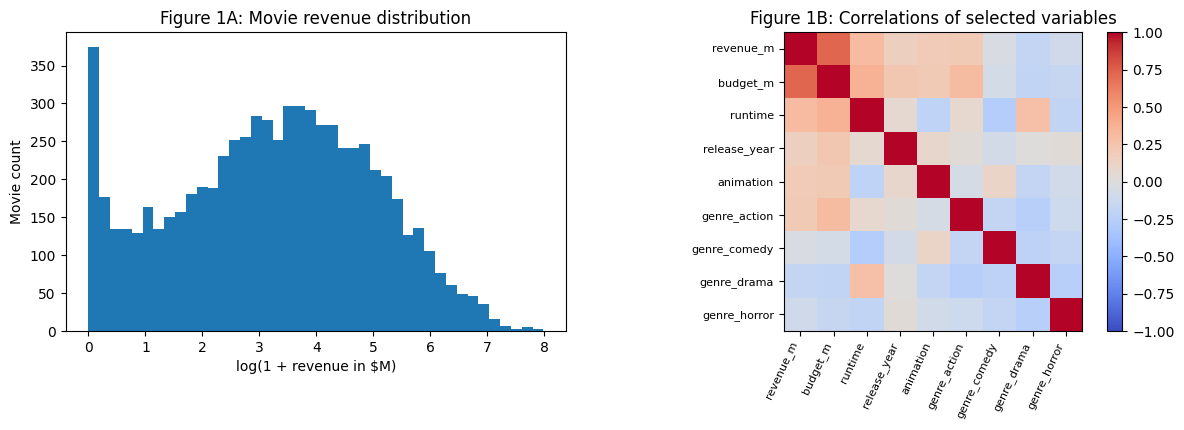

In [3]:
fig,axs=plt.subplots(1,2,figsize=(12,4.4))
axs[0].hist(np.log1p(df.revenue_m),bins=42)
axs[0].set(xlabel='log(1 + revenue in $M)',ylabel='Movie count',title='Figure 1A: Movie revenue distribution')
cor=df[['revenue_m','budget_m','runtime','release_year','animation','genre_action','genre_comedy','genre_drama','genre_horror']].corr()
im=axs[1].imshow(cor,cmap='coolwarm',vmin=-1,vmax=1)
axs[1].set_xticks(range(len(cor)),cor.columns,rotation=65,ha='right',fontsize=8)
axs[1].set_yticks(range(len(cor)),cor.columns,fontsize=8)
fig.colorbar(im,ax=axs[1],fraction=.045)
axs[1].set_title('Figure 1B: Correlations of selected variables')
plt.tight_layout();plt.show()

## 4. Benchmark: Ordinary least squares using all controls

In [4]:
def metrics(model,xtr,xts,label):
    a=np.asarray(model.predict(xtr)).ravel()
    b=np.asarray(model.predict(xts)).ravel()
    return {'Model':label,'Train R2':r2_score(y_train,a),'Test R2':r2_score(y_test,b),
            'Train RMSE ($M)':np.sqrt(mean_squared_error(y_train,a)),
            'Test RMSE ($M)':np.sqrt(mean_squared_error(y_test,b)),
            'Test MAE ($M)':mean_absolute_error(y_test,b)}
ols=LinearRegression().fit(X_train,y_train)
results=[metrics(ols,X_train,X_test,'Week 1 linear controls')]
print(pd.DataFrame(results).round(3).to_string(index=False))

                 Model  Train R2  Test R2  Train RMSE ($M)  Test RMSE ($M)  Test MAE ($M)
Week 1 linear controls     0.545    0.514          125.937         112.443         63.953


## 5. Forward and backward feature selection

In [5]:
# Faster CV evaluation for many greedy candidate subsets: train-fold OLS predictions.
# The intercept is included in every fit; all folds are built from training data only.
A=X_train.to_numpy(dtype=float)
y=y_train.to_numpy(dtype=float)
folds=list(cv.split(A))
cv_cache={}
def subset_cv_rmse(indices):
    key=tuple(sorted(indices))
    if key not in cv_cache:
        losses=[]
        for fit_ix,val_ix in folds:
            reg=LinearRegression().fit(A[np.ix_(fit_ix,key)],y[fit_ix])
            p=reg.predict(A[np.ix_(val_ix,key)])
            losses.append(np.sqrt(mean_squared_error(y[val_ix],p)))
        cv_cache[key]=float(np.mean(losses))
    return cv_cache[key]

def greedy_selection(direction):
    included=[] if direction=='forward' else list(range(len(features)))
    path=[]
    while True:
        if included:
            path.append({'Size':len(included),'CV RMSE ($M)':subset_cv_rmse(included),'Indices':tuple(sorted(included))})
        if len(included)==len(features) and direction=='forward':break
        if len(included)==1 and direction=='backward':break
        remaining=[j for j in range(len(features)) if j not in included]
        candidate_sets=[included+[j] for j in remaining] if direction=='forward' else [[k for k in included if k!=j] for j in included]
        scores=[subset_cv_rmse(option) for option in candidate_sets]
        included=candidate_sets[int(np.argmin(scores))]
    table=pd.DataFrame(path)
    best=table.loc[table['CV RMSE ($M)'].idxmin()]
    return table,best

forward_path,forward_best=greedy_selection('forward')
backward_path,backward_best=greedy_selection('backward')
for name,row in [('Forward selection',forward_best),('Backward selection',backward_best)]:
    print(name,': best size',int(row['Size']),'mean CV RMSE',round(row['CV RMSE ($M)'],3),'$M')
    print('Selected:',[features[i] for i in row['Indices']])
print('Subsets evaluated:',len(cv_cache))

Forward selection : best size 13 mean CV RMSE 126.026 $M
Selected: ['budget_m', 'runtime', 'animation', 'genre_action', 'genre_comedy', 'genre_drama', 'genre_horror', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_12']
Backward selection : best size 14 mean CV RMSE 126.026 $M
Selected: ['budget_m', 'runtime', 'animation', 'genre_action', 'genre_comedy', 'genre_drama', 'genre_horror', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_10']
Subsets evaluated: 359


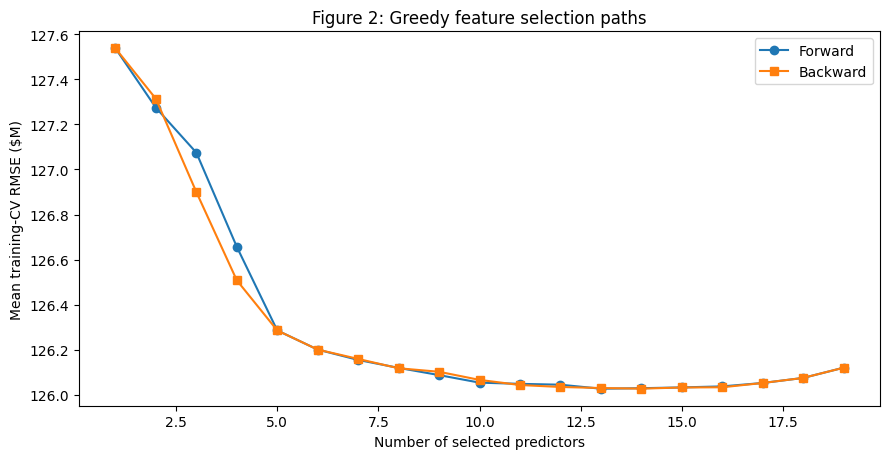

In [6]:
fig,ax=plt.subplots(figsize=(9,4.7))
ax.plot(forward_path['Size'],forward_path['CV RMSE ($M)'],marker='o',label='Forward')
ax.plot(backward_path['Size'],backward_path['CV RMSE ($M)'],marker='s',label='Backward')
ax.set(xlabel='Number of selected predictors',ylabel='Mean training-CV RMSE ($M)',title='Figure 2: Greedy feature selection paths')
ax.legend();plt.tight_layout();plt.show()
selection_models={}
for name,best in [('Forward selection',forward_best),('Backward selection',backward_best)]:
    cols=[features[i] for i in best['Indices']]
    model=LinearRegression().fit(X_train[cols],y_train)
    selection_models[name]=(model,cols)
    results.append(metrics(model,X_train[cols],X_test[cols],name))

## 6. Principal component regression: PCR

In [7]:
def tune_components(method):
    scores=[]
    for count in range(1,len(features)+1):
        if method=='PCR':
            model=Pipeline([('scale',StandardScaler()),('components',PCA(n_components=count)),('regression',LinearRegression())])
        else:
            model=Pipeline([('scale',StandardScaler()),('regression',PLSRegression(n_components=count,scale=False,max_iter=1000))])
        fold_rmse=-cross_val_score(model,X_train,y_train,cv=cv,scoring='neg_root_mean_squared_error',n_jobs=1)
        scores.append({'Components':count,'CV RMSE ($M)':fold_rmse.mean(),'CV SD ($M)':fold_rmse.std()})
    grid=pd.DataFrame(scores)
    chosen=int(grid.loc[grid['CV RMSE ($M)'].idxmin(),'Components'])
    if method=='PCR':
        fitted=Pipeline([('scale',StandardScaler()),('components',PCA(n_components=chosen)),('regression',LinearRegression())]).fit(X_train,y_train)
    else:
        fitted=Pipeline([('scale',StandardScaler()),('regression',PLSRegression(n_components=chosen,scale=False,max_iter=1000))]).fit(X_train,y_train)
    print(f'{method}: best components = {chosen}; training-CV RMSE = ${grid["CV RMSE ($M)"].min():.2f}M')
    return grid,chosen,fitted
pcr_grid,pcr_n,pcr_model=tune_components('PCR')
results.append(metrics(pcr_model,X_train,X_test,'PCR'))
print('Selected PCR cumulative predictor variance explained:',round(pcr_model.named_steps['components'].explained_variance_ratio_.sum(),4))

PCR: best components = 19; training-CV RMSE = $126.12M
Selected PCR cumulative predictor variance explained: 1.0


## 7. Partial least squares regression: PLSR


PLSR: best components = 10; training-CV RMSE = $126.12M


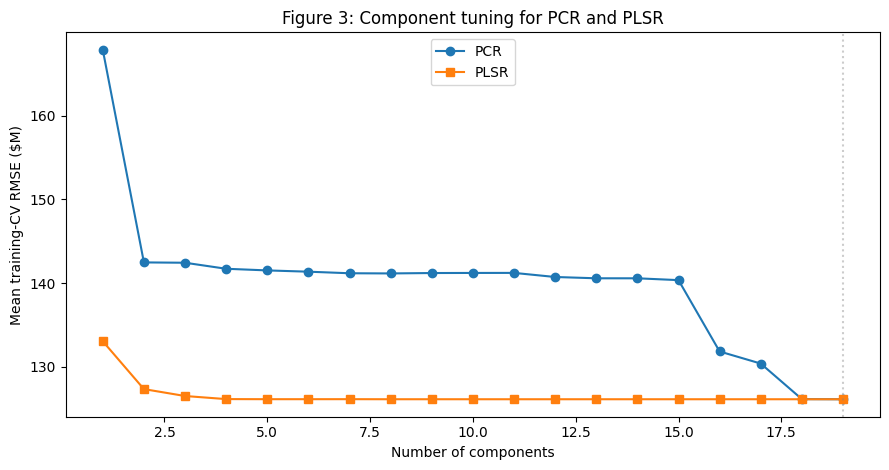

In [8]:
plsr_grid,plsr_n,plsr_model=tune_components('PLSR')
results.append(metrics(plsr_model,X_train,X_test,'PLSR'))
fig,ax=plt.subplots(figsize=(9,4.8))
ax.plot(pcr_grid.Components,pcr_grid['CV RMSE ($M)'],marker='o',label='PCR')
ax.plot(plsr_grid.Components,plsr_grid['CV RMSE ($M)'],marker='s',label='PLSR')
ax.axvline(pcr_n,color='gray',alpha=.4,linestyle=':')
ax.set(xlabel='Number of components',ylabel='Mean training-CV RMSE ($M)',title='Figure 3: Component tuning for PCR and PLSR')
ax.legend();plt.tight_layout();plt.show()

## 8. Compare held-out results and inspect overfitting

                        Train R2  Test R2  Train RMSE ($M)  Test RMSE ($M)  Test MAE ($M)
Model                                                                                    
Week 1 linear controls     0.545    0.514          125.937         112.443         63.953
Forward selection          0.545    0.514          125.957         112.413         63.901
Backward selection         0.545    0.513          125.985         112.576         64.066
PCR                        0.545    0.514          125.937         112.443         63.953
PLSR                       0.545    0.514          125.937         112.442         63.952


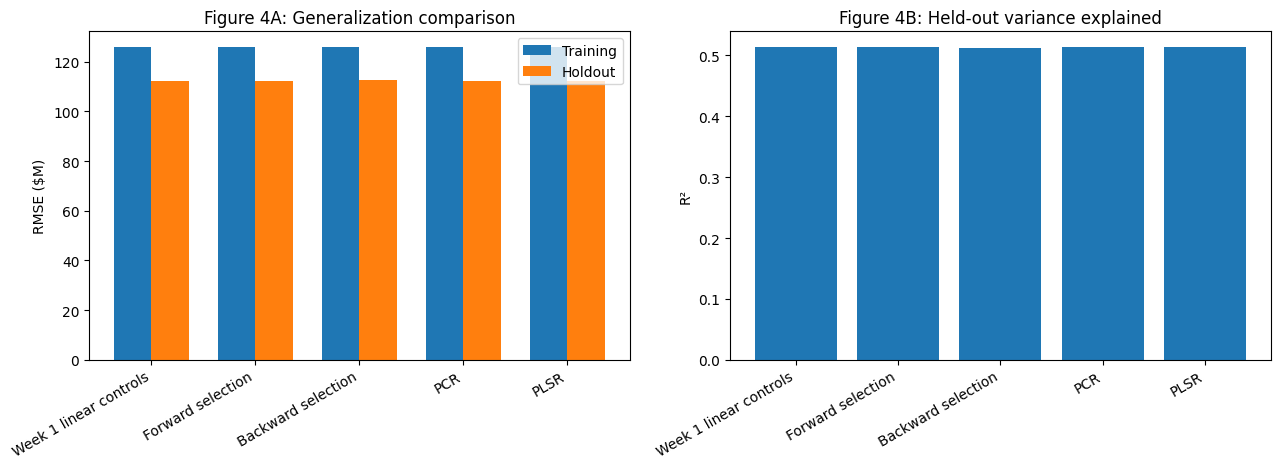

In [9]:
comparison=pd.DataFrame(results).set_index('Model')
print(comparison.round(3).to_string())
fig,axes=plt.subplots(1,2,figsize=(13,4.8))
x=np.arange(len(comparison))
axes[0].bar(x-.18,comparison['Train RMSE ($M)'],width=.36,label='Training')
axes[0].bar(x+.18,comparison['Test RMSE ($M)'],width=.36,label='Holdout')
axes[0].set_xticks(x,comparison.index,rotation=30,ha='right')
axes[0].set(ylabel='RMSE ($M)',title='Figure 4A: Generalization comparison')
axes[0].legend()
axes[1].bar(x,comparison['Test R2'])
axes[1].set_xticks(x,comparison.index,rotation=30,ha='right')
axes[1].set(ylabel='R²',title='Figure 4B: Held-out variance explained')
plt.tight_layout();plt.show()

## 9. Predicted revenue and residuals

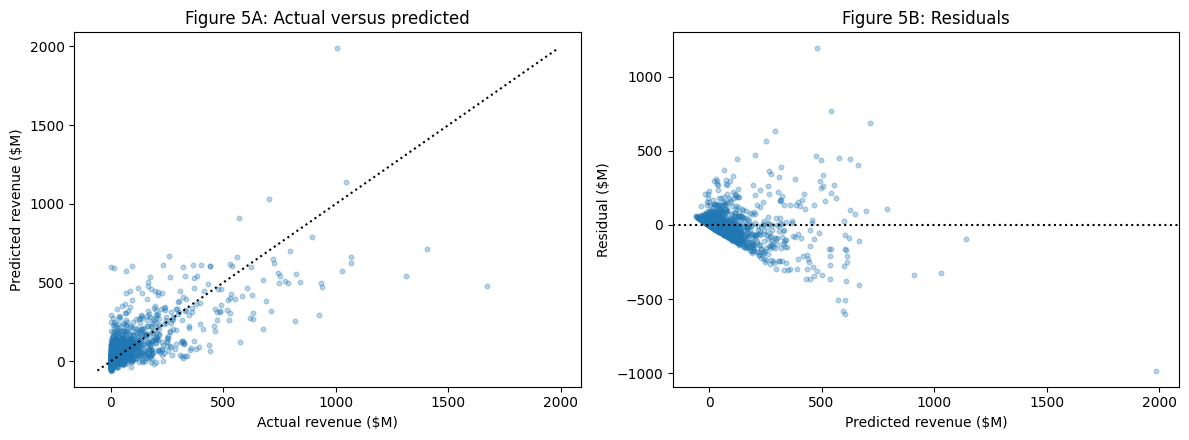

Method selected using training CV: Forward selection


In [10]:
cv_methods={'Forward selection':(float(forward_best['CV RMSE ($M)']),selection_models['Forward selection'][0],selection_models['Forward selection'][1]),
            'Backward selection':(float(backward_best['CV RMSE ($M)']),selection_models['Backward selection'][0],selection_models['Backward selection'][1]),
            'PCR':(float(pcr_grid['CV RMSE ($M)'].min()),pcr_model,features),
            'PLSR':(float(plsr_grid['CV RMSE ($M)'].min()),plsr_model,features)}
chosen_name=min(cv_methods,key=lambda name:cv_methods[name][0])
_,chosen_model,chosen_cols=cv_methods[chosen_name]
pred=np.asarray(chosen_model.predict(X_test[chosen_cols])).ravel()
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].scatter(y_test,pred,alpha=.3,s=11)
low=min(float(y_test.min()),float(pred.min())); high=max(float(y_test.max()),float(pred.max()))
axes[0].plot([low,high],[low,high],color='black',linestyle=':')
axes[0].set(xlabel='Actual revenue ($M)',ylabel='Predicted revenue ($M)',title='Figure 5A: Actual versus predicted')
axes[1].scatter(pred,y_test-pred,alpha=.3,s=11)
axes[1].axhline(0,color='black',linestyle=':')
axes[1].set(xlabel='Predicted revenue ($M)',ylabel='Residual ($M)',title='Figure 5B: Residuals')
plt.tight_layout();plt.show()
print('Method selected using training CV:',chosen_name)

## 10. Conclusions and implications for Milestone One

In [11]:
base=comparison.loc['Week 1 linear controls']
print(f'Analyzed {len(df):,} movies, with {len(train):,} training and {len(test):,} held-out observations.')
print(f'Linear-controls baseline: test R²={base["Test R2"]:.3f}; RMSE=${base["Test RMSE ($M)"]:.2f}M.')
for name in ['Forward selection','Backward selection','PCR','PLSR']:
    r=comparison.loc[name]
    print(f'{name}: test R²={r["Test R2"]:.3f}; RMSE=${r["Test RMSE ($M)"]:.2f}M; MAE=${r["Test MAE ($M)"]:.2f}M; change from baseline RMSE=${r["Test RMSE ($M)"]-base["Test RMSE ($M)"]:+.2f}M.')
print('Forward selected features:',[features[j] for j in forward_best['Indices']])
print('Backward selected features:',[features[j] for j in backward_best['Indices']])
print('PCR selected component count:',pcr_n,'; PLSR selected component count:',plsr_n)
print('CV-selected Week 3 display model:',chosen_name)
print('Conclusion: Prefer methods that generalize to unseen movies, not methods that fit training movies most tightly.')

Analyzed 7,079 movies, with 5,663 training and 1,416 held-out observations.
Linear-controls baseline: test R²=0.514; RMSE=$112.44M.
Forward selection: test R²=0.514; RMSE=$112.41M; MAE=$63.90M; change from baseline RMSE=$-0.03M.
Backward selection: test R²=0.513; RMSE=$112.58M; MAE=$64.07M; change from baseline RMSE=$+0.13M.
PCR: test R²=0.514; RMSE=$112.44M; MAE=$63.95M; change from baseline RMSE=$+0.00M.
PLSR: test R²=0.514; RMSE=$112.44M; MAE=$63.95M; change from baseline RMSE=$-0.00M.
Forward selected features: ['budget_m', 'runtime', 'animation', 'genre_action', 'genre_comedy', 'genre_drama', 'genre_horror', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_12']
Backward selected features: ['budget_m', 'runtime', 'animation', 'genre_action', 'genre_comedy', 'genre_drama', 'genre_horror', 'month_3', 'month_4', 'month_5', 'month_6', 'month_7', 'month_8', 'month_10']
PCR selected component count: 19 ; PLSR selected component count: 10
CV-selected Week 3 display model: For